# Pasos 6 y 7 · Evaluación final y explicabilidad

Se usa el modelo elegido por PR-AUC de validación en el paso 5, junto con su preprocesador del paso 3. El score genera una alerta de revisión cuando alcanza el umbral. Los umbrales se fijan en validación antes de puntuar prueba.

La simulación suma el monto original de cada fraude omitido y un costo fijo por cada alerta falsa. Se tratan los montos originales como USD para el ejercicio. El caso principal usa 5 USD por alerta falsa y la sensibilidad usa 2 y 10 USD. Se supone que detectar un fraude evita la pérdida completa y que el costo adicional de las alertas verdaderas es cero.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, average_precision_score, confusion_matrix

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data import load_raw, time_split, xy
from src.evaluate import best_threshold, expected_cost, summarize

model_path = project_root / "models/fraud_model.joblib"
if not model_path.is_file():
    raise FileNotFoundError("Ejecuta notebooks/03_models.ipynb completo para generar el modelo.")
artifact = joblib.load(model_path)
if "validation_scores" not in artifact:
    raise ValueError("Vuelve a ejecutar el paso 5 para guardar los puntajes de validación de todos los modelos.")

SEED = 42
FP_COST = 5.0
REVIEW_COSTS = (2.0, FP_COST, 10.0)
_, val, test = time_split(load_raw(project_root / "data/raw/creditcard.csv"))
X_va_raw, y_va = xy(val)
amt_va = val["Amount"].to_numpy()
pre = artifact["preprocessor"]
feature_columns = artifact["feature_columns"]
model_name, model = artifact["name"], artifact["model"]

def risk_scores(estimator, features):
    if model_name == "isolation_forest":
        return -estimator.score_samples(features)
    return estimator.predict_proba(features)[:, 1]

X_va = pre.transform(X_va_raw)[feature_columns]
s_va = risk_scores(model, X_va)
comparison_scores = artifact["validation_scores"]
pd.testing.assert_index_equal(comparison_scores.index, val.index)
np.testing.assert_array_equal(s_va, comparison_scores[model_name].to_numpy())
validation_ap = average_precision_score(y_va, s_va)
np.testing.assert_allclose(validation_ap, artifact["validation_metrics"]["pr_auc"])
print(f"Modelo del paso 5: {model_name} · PR-AUC de validación: {validation_ap:.6f}")
print(f"Validación: {len(val):,} transacciones · {y_va.sum()} fraudes")

## Umbral y curvas de validación

Se evalúa cada score distinto como posible corte, junto con la opción de no alertar. Los scores iguales activan la misma decisión. Si dos cortes tienen el mismo costo, se elige el que genera menos alertas. La precisión promedio (AP) se reporta como PR-AUC para mantener la misma definición que en los pasos 4 y 5.

In [2]:
operating_points = {
    cost: best_threshold(y_va, s_va, amt_va, fp_cost=cost)
    for cost in REVIEW_COSTS
}
thr, cost_va, cutoffs, costs = operating_points[FP_COST]
np.testing.assert_allclose(cost_va, expected_cost(y_va, s_va, amt_va, thr, FP_COST))
no_alerts_va = expected_cost(y_va, s_va, amt_va, np.inf, FP_COST)

validation_operating_points = pd.DataFrame([
    {"Costo por alerta falsa (USD)": fp_cost, "Umbral": cutoff, "Costo de validación (USD)": cost}
    for fp_cost, (cutoff, cost, _, _) in operating_points.items()
])
validation_operating_points.round(6)

,Costo por alerta falsa (USD),Umbral,Costo de validación (USD)
0,2.0,0.574391,182.3
1,5.0,0.574391,206.3
2,10.0,0.574391,246.3


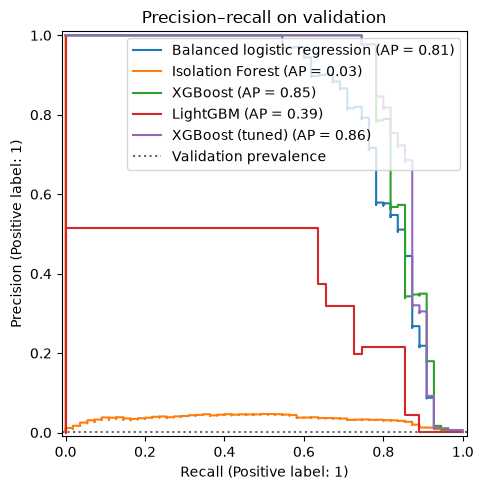

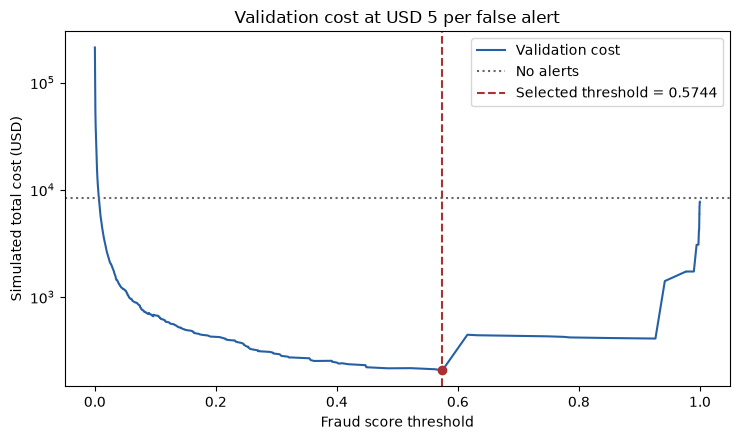

In [3]:
figure_dir = project_root / "reports/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
model_labels = {
    "logreg_balanced": "Balanced logistic regression",
    "isolation_forest": "Isolation Forest",
    "xgboost": "XGBoost",
    "xgboost_tuned": "XGBoost (tuned)",
    "lightgbm": "LightGBM",
}

fig, ax = plt.subplots(figsize=(7.5, 5))
for name in comparison_scores.columns:
    PrecisionRecallDisplay.from_predictions(
        y_va, comparison_scores[name], name=model_labels[name], ax=ax,
    )
ax.axhline(y_va.mean(), color="0.4", linestyle=":", label="Validation prevalence")
ax.set_title("Precision–recall on validation")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(figure_dir / "05_pr_curves.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(cutoffs[:0:-1], costs[:0:-1], color="#2660a4", label="Validation cost")
ax.axhline(no_alerts_va, color="0.4", linestyle=":", label="No alerts")
if np.isfinite(thr):
    ax.axvline(thr, color="#a83232", linestyle="--", label=f"Selected threshold = {thr:.4f}")
    ax.scatter([thr], [cost_va], color="#a83232", zorder=3)
ax.set(
    xlabel="Fraud score threshold",
    ylabel="Simulated total cost (USD)",
    title="Validation cost at USD 5 per false alert",
    yscale="symlog",
)
ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "06_cost_vs_threshold.png", dpi=150)
plt.show()

## Evaluación en prueba

Se generan los scores de prueba una sola vez. Para el escenario principal y la sensibilidad, se aplican los umbrales ya fijados en validación. La referencia sin alertas pierde la suma de los montos de todos los fraudes de prueba.

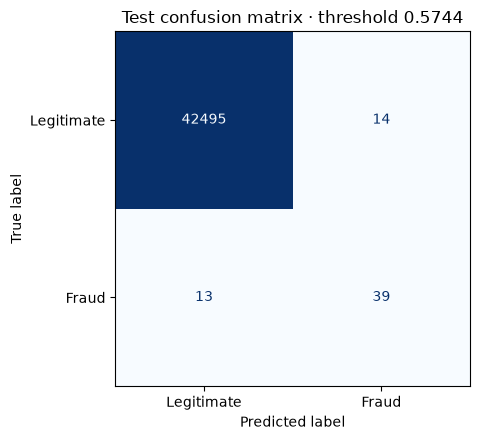

In [4]:
X_te_raw, y_te = xy(test)
amt_te = test["Amount"].to_numpy()
X_te = pre.transform(X_te_raw)[feature_columns]
s_te = risk_scores(model, X_te)
flagged = s_te >= thr
matrix = confusion_matrix(y_te, flagged, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
cost_nothing = expected_cost(y_te, s_te, amt_te, np.inf, FP_COST)
missed_amount = amt_te[y_te.eq(1).to_numpy() & ~flagged].sum()
cost_te = expected_cost(y_te, s_te, amt_te, thr, FP_COST)
np.testing.assert_allclose(cost_te, missed_amount + fp * FP_COST)
savings = cost_nothing - cost_te
test_metrics = summarize(y_te, s_te, model_name)

print(f"Prueba: {len(y_te):,} transacciones · {int(y_te.sum())} fraudes")
print(f"PR-AUC: {test_metrics['pr_auc']:.6f} · ROC-AUC: {test_metrics['roc_auc']:.6f}")
print(f"Umbral fijado en validación: {thr:.9f}")
print(f"Alertas: {tp + fp} · TP={tp}, FP={fp}, FN={fn}, TN={tn}")
print(f"Precisión: {tp / (tp + fp):.2%} · recall: {tp / (tp + fn):.2%}" if tp + fp else "Sin alertas · recall: 0.00%")
print(f"Fraude omitido: {missed_amount:,.2f} USD · falsas alertas: {fp * FP_COST:,.2f} USD")
print(f"Costo en prueba: {cost_te:,.2f} USD · sin alertas: {cost_nothing:,.2f} USD")
print(f"Ahorro simulado: {savings:,.2f} USD ({savings / cost_nothing:.2%})")

fig, ax = plt.subplots(figsize=(6, 4.5))
ConfusionMatrixDisplay(matrix, display_labels=["Legitimate", "Fraud"]).plot(
    ax=ax, values_format="d", colorbar=False, cmap="Blues",
)
ax.set_title(f"Test confusion matrix · threshold {thr:.4f}")
fig.tight_layout()
fig.savefig(figure_dir / "07_confusion_test.png", dpi=150)
plt.show()

## Incertidumbre del PR-AUC

Se remuestrean transacciones de prueba con reemplazo, manteniendo fijos los scores del modelo. El intervalo percentil del 95 % resume la variabilidad del PR-AUC para esta muestra bajo el supuesto de observaciones independientes. El remuestreo por transacción no representa cambios temporales ni la incertidumbre del entrenamiento.

In [5]:
rng = np.random.default_rng(SEED)
labels_te = y_te.to_numpy()
boot_ap = []
for _ in range(1000):
    indices = rng.integers(0, len(labels_te), size=len(labels_te))
    labels = labels_te[indices]
    if labels.any():
        boot_ap.append(average_precision_score(labels, s_te[indices]))
lo, hi = np.percentile(boot_ap, [2.5, 97.5])
print(f"PR-AUC en prueba: {test_metrics['pr_auc']:.6f} · IC95 % [{lo:.6f}, {hi:.6f}]")
print(f"Réplicas válidas: {len(boot_ap):,} de 1,000 (semilla {SEED})")

## Errores del escenario principal

Se contrastan los fraudes detectados y omitidos en prueba. Para seleccionar las variables de esta comparación se mide, en validación, cuánto cae el PR-AUC al permutar cada variable. Las horas se agrupan desde el primer registro del dataset. Los componentes PCA son anónimos y sus valores no permiten identificar comportamientos de negocio.

In [6]:
def score_average_precision(estimator, features, labels):
    return average_precision_score(labels, risk_scores(estimator, features))

importance = permutation_importance(
    model, X_va, y_va, scoring=score_average_precision, n_repeats=3, random_state=SEED,
)
ap_drop = pd.Series(importance.importances_mean, index=feature_columns, name="Caída media de AP en validación")
top_features = ap_drop.nlargest(3).index
frauds = test.loc[test["Class"].eq(1)].copy()
frauds["Detectado"] = flagged[labels_te == 1]
frauds["Hora relativa"] = ((frauds["Time"] // 3600) % 24).astype(int)
missed, detected = frauds.loc[~frauds["Detectado"]], frauds.loc[frauds["Detectado"]]

features_summary = pd.DataFrame({
    ap_drop.name: ap_drop[top_features],
    "Mediana de omitidos": missed[top_features].median(),
    "Mediana de detectados": detected[top_features].median(),
})
display(features_summary.round(4))

if not missed.empty and not detected.empty:
    hours = missed["Hora relativa"].value_counts().sort_index()
    busiest_hour = int(hours.idxmax())
    biggest_shift = (features_summary["Mediana de omitidos"] - features_summary["Mediana de detectados"]).abs().idxmax()
    print(f"1. Se omitieron {len(missed)} de {len(frauds)} fraudes ({len(missed) / len(frauds):.1%}), "
          f"que suman {missed_amount:,.2f} USD ({missed_amount / cost_nothing:.1%} del monto fraudulento).")
    print(f"2. Mediana del monto: {missed['Amount'].median():,.2f} USD en omitidos y "
          f"{detected['Amount'].median():,.2f} USD en detectados. El mayor omitido fue de {missed['Amount'].max():,.2f} USD.")
    print(f"3. Los omitidos se repartieron en {len(hours)} horas relativas. En la hora {busiest_hour:02d} "
          f"hubo {hours.max()} de los {len(missed)} omitidos y {frauds['Hora relativa'].eq(busiest_hour).sum()} fraudes en total.")
    print(f"4. Entre las tres variables de mayor importancia en validación, {biggest_shift} mostró "
          f"la mayor diferencia absoluta de medianas: {missed[biggest_shift].median():.3f} en omitidos y "
          f"{detected[biggest_shift].median():.3f} en detectados.")
else:
    print(f"Fraudes omitidos: {len(missed)} · detectados: {len(detected)}. La comparación de ambos grupos requiere casos en cada uno.")

,Caída media de AP en validación,Mediana de omitidos,Mediana de detectados
V4,0.1079,1.0870,5.1048
V12,0.0380,0.1446,-5.2672
V14,0.0353,-1.4256,-8.3966


## Sensibilidad al costo de revisión

Cada umbral de la tabla minimiza el costo en validación para su tarifa correspondiente. Se aplica luego a los mismos scores de prueba. La tarifa cambia tanto la decisión de alertar como el costo de cada falsa alerta.

In [7]:
sensitivity_rows = []
for fp_cost, (cutoff, validation_cost, _, _) in operating_points.items():
    decisions = s_te >= cutoff
    _, scenario_fp, scenario_fn, scenario_tp = confusion_matrix(y_te, decisions, labels=[0, 1]).ravel()
    test_cost = expected_cost(y_te, s_te, amt_te, cutoff, fp_cost)
    sensitivity_rows.append({
        "Costo por alerta falsa (USD)": fp_cost,
        "Umbral": cutoff,
        "Costo de validación (USD)": validation_cost,
        "TP en prueba": scenario_tp,
        "FP en prueba": scenario_fp,
        "FN en prueba": scenario_fn,
        "Costo de prueba (USD)": test_cost,
        "Ahorro en prueba (%)": 100 * (cost_nothing - test_cost) / cost_nothing,
    })
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.round({"Umbral": 6, "Costo de validación (USD)": 2, "Costo de prueba (USD)": 2, "Ahorro en prueba (%)": 2})

,Costo por alerta falsa (USD),Umbral,Costo de validación (USD),TP en prueba,FP en prueba,FN en prueba,Costo de prueba (USD),Ahorro en prueba (%)
0,2.0,0.574391,182.3,39,14,13,2400.4,61.09
1,5.0,0.574391,206.3,39,14,13,2442.4,60.41
2,10.0,0.574391,246.3,39,14,13,2512.4,59.27


El conjunto de datos cubre aproximadamente dos días y la muestra de prueba contiene pocos fraudes. Los scores sirven para ordenar el riesgo y se emplean como tales en esta evaluación. Los costos representan una simulación con variables anonimizadas. El paso 4 reportó las métricas de prueba de la línea base. Para el ganador del paso 5 y los tres cortes de este notebook, todas las decisiones se tomaron usando validación.

## Paso 7 · Explicabilidad del modelo final con SHAP

Se mantienen el modelo, el preprocesador, los scores de prueba y el umbral del paso 6. La muestra incluye todos los fraudes de prueba y hasta 2,000 transacciones legítimas elegidas sin reemplazo con la semilla 42. El ranking global describe esta muestra con sobrerrepresentación de fraude.

TreeSHAP explica el margen de XGBoost, en unidades de log-odds. Para cada transacción, el valor base más la suma de las contribuciones recupera el margen. Su transformación logística recupera el score con el que se tomó la decisión. La parada temprana determina cuántas rondas se utilizan tanto para puntuar como para explicar.

In [8]:
import shap
from IPython.display import Markdown
from scipy.special import expit
from xgboost import XGBClassifier

if not isinstance(model, XGBClassifier):
    raise TypeError("Este análisis requiere el XGBoost seleccionado en el paso 5.")

fraud_rows = X_te.loc[y_te.eq(1)]
legitimate_rows = X_te.loc[y_te.eq(0)]
X_shap = pd.concat([
    fraud_rows,
    legitimate_rows.sample(n=min(2_000, len(legitimate_rows)), random_state=SEED),
])
assert X_shap.index.is_unique and X_shap.index.isin(X_te.index).all()
assert X_shap.index[:len(fraud_rows)].equals(fraud_rows.index)
sample_positions = X_te.index.get_indexer(X_shap.index)
sample_scores = s_te[sample_positions]

booster = model.get_booster()
rounds_used = model.best_iteration + 1
scoring_booster = booster[:rounds_used]
explainer = shap.TreeExplainer(scoring_booster, feature_perturbation="tree_path_dependent")
explanations = explainer(X_shap)
assert explanations.values.shape == X_shap.shape
assert np.isfinite(explanations.values).all()
margins = np.asarray(explanations.base_values, dtype=float) + explanations.values.sum(axis=1, dtype=float)
np.testing.assert_allclose(margins, model.predict(X_shap, output_margin=True), rtol=1e-5, atol=1e-5)
np.testing.assert_allclose(expit(margins), sample_scores, rtol=1e-5, atol=1e-6)

score_error = np.max(np.abs(expit(margins) - sample_scores))
display(Markdown(
    f"**Muestra.** {len(X_shap):,} transacciones, {len(fraud_rows)} fraudes y "
    f"{len(X_shap) - len(fraud_rows):,} legítimas.  \n"
    f"**Modelo.** {rounds_used} de {booster.num_boosted_rounds()} rondas guardadas.  \n"
    f"**Error máximo al reconstruir el score.** {score_error:.2e}."
))

**Muestra.** 2,052 transacciones, 52 fraudes y 2,000 legítimas.  
**Modelo.** 919 de 1019 rondas guardadas.  
**Error máximo al reconstruir el score.** 2.51e-07.

### Importancia global

Cada punto del primer gráfico representa una transacción. El rojo indica valores altos de la variable y el azul, valores bajos. Las contribuciones a la derecha elevan el score de fraude y las de la izquierda lo reducen. El segundo gráfico ordena las variables por la media de la contribución absoluta, que mide magnitud sin signo.

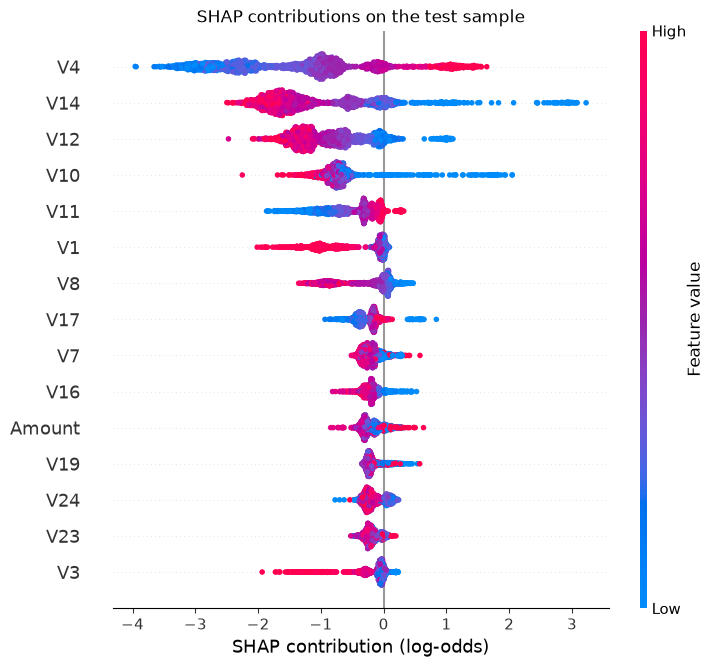

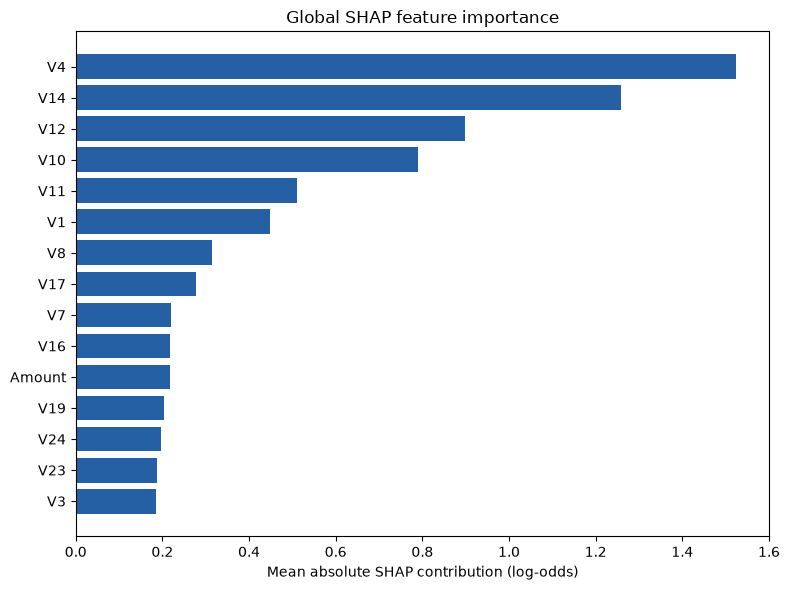

,V4,V14,V12
Legítimas,-1.1682,-1.4491,-0.9612
Fraudes,0.9745,2.7600,0.9074


In [9]:
np.random.seed(SEED)
shap.plots.beeswarm(explanations, max_display=15, group_remaining_features=False, show=False)
ax = plt.gca()
ax.set(title="SHAP contributions on the test sample", xlabel="SHAP contribution (log-odds)")
ax.figure.savefig(figure_dir / "08_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(ax.figure)

mean_abs_shap = pd.Series(np.abs(explanations.values).mean(axis=0), index=feature_columns)
top_shap = mean_abs_shap.nlargest(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_shap.index, top_shap, color="#2660a4")
ax.set(title="Global SHAP feature importance", xlabel="Mean absolute SHAP contribution (log-odds)")
fig.tight_layout()
fig.savefig(figure_dir / "09_shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

global_leaders = mean_abs_shap.nlargest(3).index
sample_labels = y_te.loc[X_shap.index].to_numpy()
shap_by_class = pd.DataFrame(explanations.values, columns=feature_columns).groupby(sample_labels).median()
display(shap_by_class.loc[:, global_leaders].rename(index={0: "Legítimas", 1: "Fraudes"}).round(4))

### Dos fraudes de prueba

Se selecciona el fraude de mayor monto original de cada grupo del paso 6. La cascada suma los aportes al valor base hasta llegar al margen individual. La tabla muestra el score resultante y la decisión al aplicar el umbral fijado en validación.

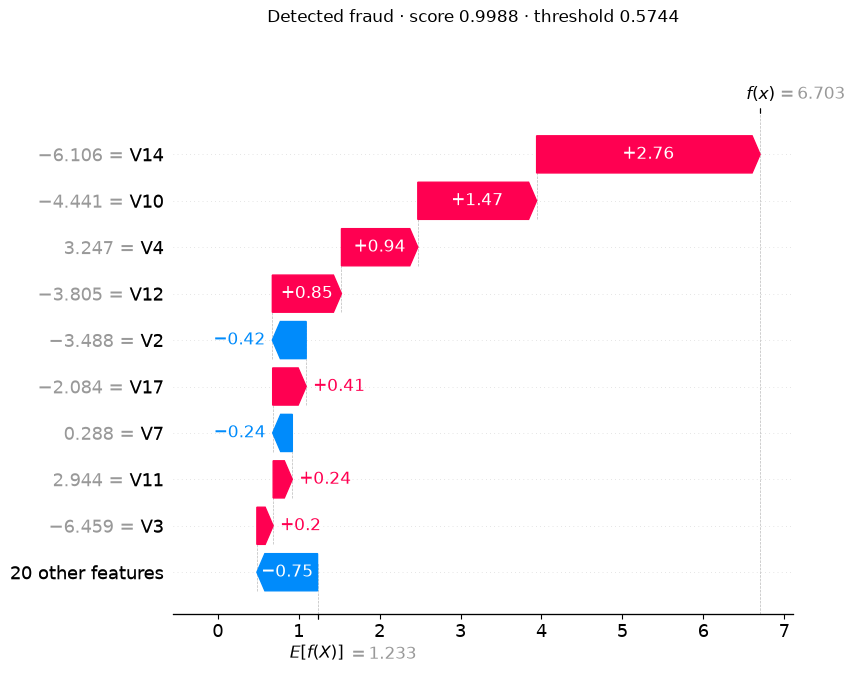

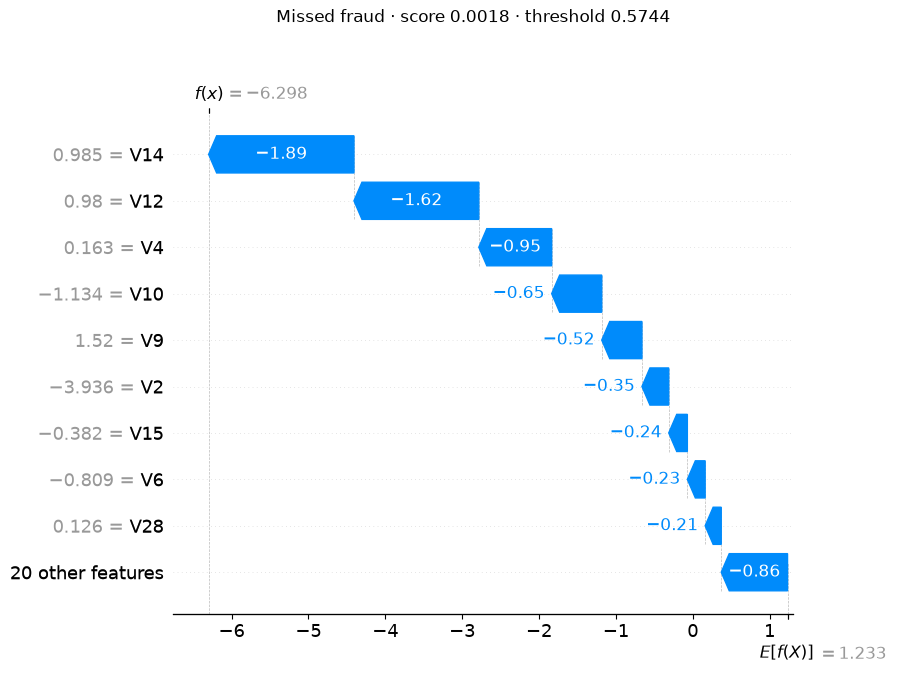

,Caso,Monto (USD),Margen,Score,Umbral,Mayores aportes (log-odds)
0,Detectado,1504.93,6.702769,0.998774,0.574391,"V14 +2.762, V10 +1.468, V4 +0.944"
1,Omitido,1096.99,-6.298011,0.001837,0.574391,"V14 -1.891, V12 -1.624, V4 -0.948"


In [10]:
sample_fraud = sample_labels == 1
sample_flagged = flagged[sample_positions]
sample_amounts = X_te_raw.loc[X_shap.index, "Amount"].to_numpy()

case_rows = []
for label, plot_title, mask, filename in (
    ("Detectado", "Detected fraud", sample_fraud & sample_flagged, "10_shap_waterfall_fraud.png"),
    ("Omitido", "Missed fraud", sample_fraud & ~sample_flagged, "11_shap_waterfall_missed_fraud.png"),
):
    candidates = np.flatnonzero(mask)
    if candidates.size == 0:
        print(f"Prueba no contiene un fraude del grupo: {label.lower()}.")
        continue
    position = candidates[np.argmax(sample_amounts[candidates])]
    contributions = pd.Series(explanations.values[position], index=feature_columns)
    largest = contributions.loc[contributions.abs().nlargest(3).index]
    case_rows.append({
        "Caso": label,
        "Monto (USD)": sample_amounts[position],
        "Margen": margins[position],
        "Score": sample_scores[position],
        "Umbral": thr,
        "Mayores aportes (log-odds)": ", ".join(f"{feature} {value:+.3f}" for feature, value in largest.items()),
    })
    shap.plots.waterfall(explanations[position], max_display=10, show=False)
    fig = plt.gcf()
    fig.suptitle(f"{plot_title} · score {sample_scores[position]:.4f} · threshold {thr:.4f}", y=1.04)
    fig.savefig(figure_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

display(pd.DataFrame(case_rows).round(6))

### Comparación con la ganancia de XGBoost

La ganancia media mide la mejora del objetivo de entrenamiento en los cortes que usan cada variable. Puede favorecer variables que ofrecen más cortes candidatos. SHAP mide cuánto cambia la salida para las transacciones de la muestra. Se muestra `feature_importances_` del modelo guardado y la ganancia restringida a las rondas usadas al puntuar, para comparar ambos rankings con SHAP.

In [11]:
scoring_gain = pd.Series(scoring_booster.get_score(importance_type="gain"), dtype=float)
scoring_gain = scoring_gain.reindex(feature_columns, fill_value=0.0)
ranking = pd.DataFrame({
    "Media de |SHAP|": mean_abs_shap,
    "feature_importances_": model.feature_importances_,
    "Ganancia normalizada en rondas de scoring": scoring_gain / scoring_gain.sum(),
}).sort_values("Media de |SHAP|", ascending=False)

rank_correlation = ranking.corr(method="spearman").iloc[0, 1:]
shap_top = set(ranking.index[:5])
gain_top = set(ranking.nlargest(5, "feature_importances_").index)
display(Markdown(
    f"**Coincidencias en el top 5.** {len(shap_top & gain_top)} de 5.  \n"
    f"**Spearman con la importancia del modelo guardado.** {rank_correlation.iloc[0]:.3f}.  \n"
    f"**Spearman con la ganancia de las rondas usadas.** {rank_correlation.iloc[1]:.3f}."
))
display(ranking.round(5))

**Coincidencias en el top 5.** 5 de 5.  
**Spearman con la importancia del modelo guardado.** 0.652.  
**Spearman con la ganancia de las rondas usadas.** 0.637.

,Media de |SHAP|,feature_importances_,Ganancia normalizada en rondas de scoring
V4,1.52444,0.05997,0.05857
V14,1.25799,0.30653,0.29980
V12,0.89945,0.06108,0.06049
V10,0.79020,0.14475,0.14521
V11,0.51000,0.04234,0.04293
V1,0.44805,0.01156,0.01174
V8,0.31389,0.03160,0.03149
V17,0.27723,0.03864,0.03852
V7,0.22027,0.01380,0.01411
V16,0.21728,0.01217,0.01243


### Interpretación

V4, V14 y V12 tienen los mayores aportes absolutos medios. Para los fraudes, los tres componentes empujaron hacia un mayor riesgo en la mediana. Para las transacciones legítimas, la mediana de los tres aportes fue negativa. V14 mostró la mayor separación de medianas entre los tres componentes.

El fraude detectado recibió un score de 0.998774. V14, V10 y V4 aportaron al aumento del margen. El fraude omitido obtuvo 0.001837 frente al umbral 0.574391. En ese caso V14, V12 y V4 redujeron el margen. Ambos ejemplos corresponden al fraude de mayor monto de su grupo.

Los cinco primeros componentes son los mismos según SHAP y la importancia por ganancia de XGBoost. V4 ocupa el primer lugar por SHAP y V14 por ganancia. El orden se explica por las distintas cantidades que se miden, la contribución al margen en la muestra de prueba y la mejora del objetivo en cortes durante el entrenamiento.

V1 a V28 son componentes PCA anonimizados. SHAP identifica qué componentes impulsan un score y en qué dirección. El significado de negocio de cada componente es desconocido. En datos de producción, variables interpretables como país del comercio, tipo de tarjeta o frecuencia reciente permitirían contextualizar los aportes.